In [1]:
#%env LVM_ROOT='/Users/tonywong/Data/sdss_lvm/sdsswork/lvm'
%env LVM_SPECTRO_ANALYSIS='/Users/tonywong/Data/sdss_lvm/sdsswork/lvm/spectro/analysis'

env: LVM_SPECTRO_ANALYSIS='/Users/tonywong/Data/sdss_lvm/sdsswork/lvm/spectro/analysis'


# LVM DR20 model-file tutorial: reading and visualizing reconstructed spectral components

This notebook shows how to read an LVM DR20 DAP **model file** for the Helix Nebula example
exposure and how to visualize the spectral components stored in it. The model file complements
the standard DAP table: instead of scalar measurements per fiber, it stores spectra reconstructed
from the DAP analysis, including the observed spectrum, stellar-continuum model, gas-emission
models, joint models, and residuals.

Dataset: `DRPVER=1.2.0`, `DAPVER=1.2.0.251218`, `MJD=60191`, `EXPNUM=00004297`.

## Required Python dependencies

- **numpy**: numerical arrays and vectorized operations
- **matplotlib**: plotting
- **astropy**: reading FITS files
- **sdss-access**: locating and downloading SDSS products

```bash
pip install numpy matplotlib astropy sdss-access
```

In [2]:
# __author__   = 'Sebastian F. Sanchez and LVM team'
# __version__  = '20260420'
# __datasets__ = ['SDSS-V LVM DAP (DRPVER=1.2.0, DAPVER=1.2.0.251218, MJD=60191, EXPNUM=4297)']
# __keywords__ = ['Helix nebula', 'LVM', 'DR20', 'model spectra', 'tutorial']

## 1. Imports and SDSS access

If you run this alongside `multiprocessing`, uncomment the thread limits below **before**
importing numpy to avoid BLAS/OpenMP oversubscription.

In [3]:
import os
# for _v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS',
#            'VECLIB_MAXIMUM_THREADS', 'NUMEXPR_NUM_THREADS'):
#     os.environ[_v] = '1'

import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from astropy.io import fits
from sdss_access import Access

# nanmean over fibers that are all-NaN at some wavelengths raises RuntimeWarnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

access = Access(release='dr20', verbose=True)

## 2. Dataset definition

The model file follows the naming convention `dap-rsp108-sn20-EXPNUM.model.fits`.

In [4]:
drpver = '1.2.0'
dapver = '1.2.0.251218'
tileid = '11111'
mjd    = '60191'
expnum = '00004297'
rsp    = 'rsp108'
sn     = 'sn20'

dap_kw = dict(drpver=drpver, dapver=dapver, tileid=tileid, mjd=mjd,
              expnum=int(expnum), rspid=rsp, snlevel=sn, daptype='model')

In [5]:
access.full('lvm_dap', **dap_kw, preserve_envvars=['LVM_SPECTRO_ANALYSIS'])

'/Users/tonywong/sas/dr20/spectro/lvm/analysis/1.2.0/1.2.0.251218/0011XX/11111/60191/00004297/dap-rsp108-sn20-00004297.model.fits'

## 3. Locate (and if needed download) the model file with `sdss_access`

In [8]:
dap_model_file = access.full('lvm_dap', **dap_kw)
print('Looking for file at location',dap_model_file)
os.path.isfile(dap_model_file)

Looking for file at location /Users/tonywong/sas/dr20/spectro/lvm/analysis/1.2.0/1.2.0.251218/0011XX/11111/60191/00004297/dap-rsp108-sn20-00004297.model.fits


True

In [9]:
if not os.path.isfile(dap_model_file):
    access.remote()
    access.add('lvm_dap', **dap_kw)
    access.set_stream()
    access.commit()
    dap_model_file = access.full('lvm_dap', **dap_kw)
print(dap_model_file)

/Users/tonywong/sas/dr20/spectro/lvm/analysis/1.2.0/1.2.0.251218/0011XX/11111/60191/00004297/dap-rsp108-sn20-00004297.model.fits


## 4. Read the model cube

The cube is organized as (component, fiber, wavelength). The header keywords `NAME0`…`NAME8`
give the meaning of each component plane; the constants below name them for the rest of the
notebook.

In [10]:
# Component planes, in header order NAME0..NAME8
(OBS,       # org_spec            observed spectrum
 STAR,      # model_spec          stellar model
 JOINT,     # mod_joint_spec      stellar + gas (non-parametric) model
 GAS,       # gas_spec            observed - stellar
 RES,       # res_joint_spec      observed - joint model
 NOGAS,     # no_gas_spec         observed - gas model
 GAS_NP,    # gas_model_NP        non-parametric emission-line model
 GAS_PE,    # gas_model_PEK       parametric emission-line model
 JOINT_PE,  # mod_joint_spec_PEK  stellar + parametric gas model
 ) = range(9)


def axis_coords(header, axis=1):
    """World coordinates along a FITS axis (honours CRPIX, default 1)."""
    n = header[f'NAXIS{axis}']
    crpix = header.get(f'CRPIX{axis}', 1.0)
    return header[f'CRVAL{axis}'] + (np.arange(n) + 1 - crpix) * header[f'CDELT{axis}']


fits.info(dap_model_file)
hdr  = fits.getheader(dap_model_file)
cube = fits.getdata(dap_model_file)
wave = axis_coords(hdr, 1)
names = [hdr[f'NAME{i}'].strip() for i in range(cube.shape[0])]
print(dict(enumerate(names)))

f_scale = 1e16   # flux unit used for the quick-look y-limits below

Filename: /Users/tonywong/sas/dr20/spectro/lvm/analysis/1.2.0/1.2.0.251218/0011XX/11111/60191/00004297/dap-rsp108-sn20-00004297.model.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      22   (12401, 1754, 9)   float32   
{0: 'org_spec', 1: 'model_spec', 2: 'mod_joint_spec', 3: 'gas_spec', 4: 'res_joint_spec', 5: 'no_gas_spec', 6: 'gas_model_NP', 7: 'gas_model_PEK', 8: 'mod_joint_spec_PEK'}


## 5. One fiber around Hα + [N II] + [S II]

In a nebular target such as the Helix, the gas models dominate the strong-line windows, while
the stellar model is weak except in fibers containing foreground or field stars.

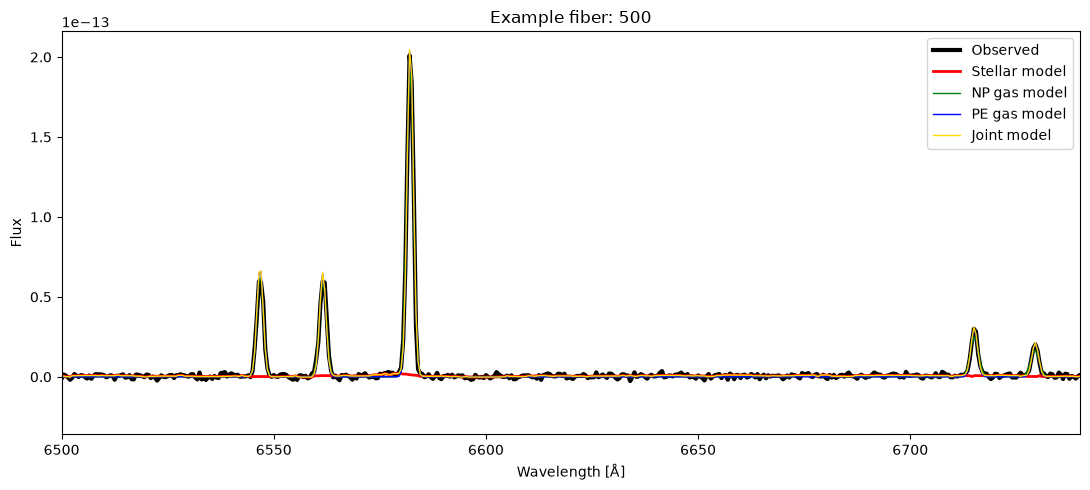

In [11]:
fib = 500
fig, ax = plt.subplots(figsize=(11, 5))
for k, label, lw, color in [(OBS,    'Observed',      3, 'black'),
                            (STAR,   'Stellar model', 2, 'red'),
                            (GAS_NP, 'NP gas model',  1, 'green'),
                            (GAS_PE, 'PE gas model',  1, 'blue'),
                            (JOINT,  'Joint model',   1, 'gold')]:
    ax.plot(wave, cube[k, fib], label=label, lw=lw, color=color)
ax.set(xlim=(6500, 6740), xlabel='Wavelength [Å]', ylabel='Flux',
       title=f'Example fiber: {fib}')
ax.legend()
fig.tight_layout()

## 6. Average spectra over the field

Collapsing along the fiber axis gives `av_spec`, shape `(Ncomponent, Nwave)`.

In [12]:
av_spec = np.nanmean(cube, axis=1)
print(av_spec.shape)

(9, 12401)


## 7. Quick-look: average observed vs. model spectra in a few windows

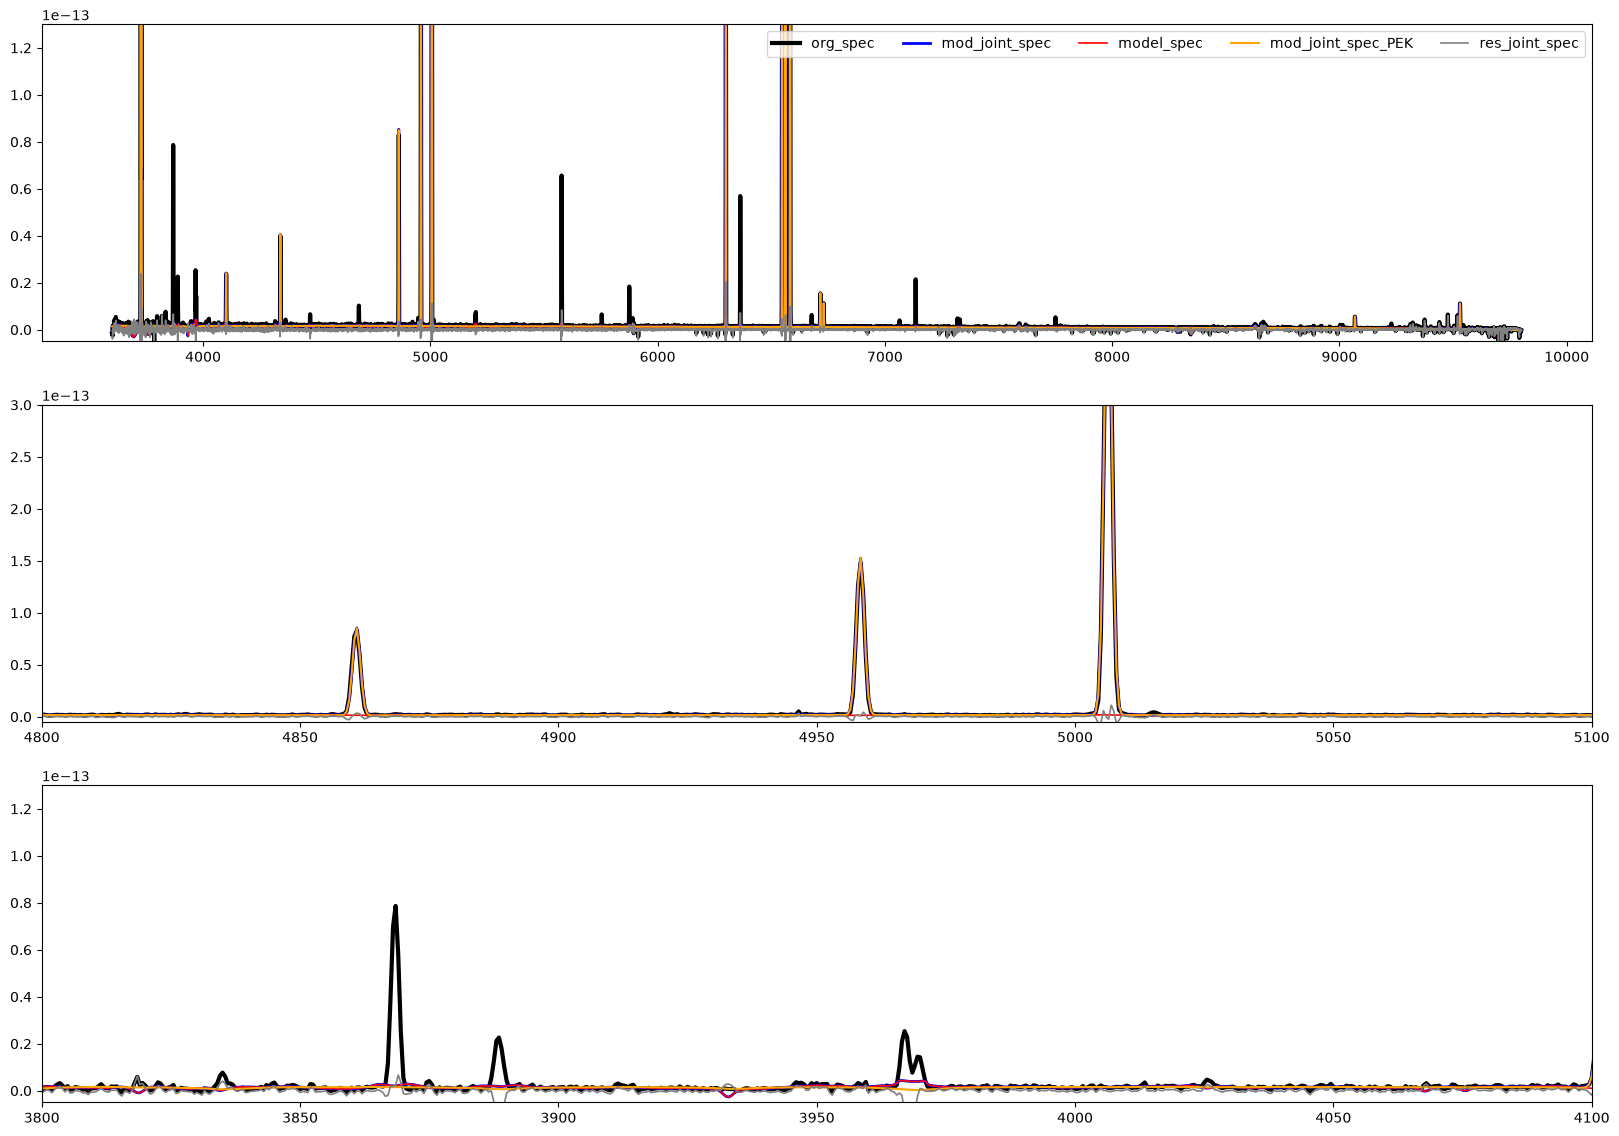

In [13]:
windows = [(None,         (-50, 1300)),   # full range
           ((4800, 5100), (-50, 3000)),   # Hβ + [O III]
           ((3800, 4100), (-50, 1300))]   # blue
curves = [(OBS, 'black', 3), (JOINT, 'blue', 2), (STAR, 'red', 1.2),
          (JOINT_PE, 'orange', 1.5), (RES, 'grey', 1.2)]

fig, axs = plt.subplots(3, 1, figsize=(20, 14))
for ax, (xlim, ylim) in zip(axs, windows):
    for k, color, lw in curves:
        ax.plot(wave, av_spec[k], color=color, lw=lw, label=names[k])
    if xlim:
        ax.set_xlim(xlim)
    ax.set_ylim(np.array(ylim) / f_scale)
axs[0].legend(ncol=len(curves))

## 8. Publication-style plotting helper

`plot_spec_now_3pg` shows a spectrum and its model components over three consecutive
wavelength ranges on a sign-preserving power-law (gamma) flux stretch, with optional zoom-in
insets on linear flux. `data_2d` is one fiber or an average, shape `(Ncomponent, Nwave)`.

In [14]:
def gamma_scale(flux, gamma):
    """Sign-preserving power-law stretch sign(f)*|f|**gamma (zero stays zero)."""
    flux = np.asarray(flux, dtype=float)
    return np.sign(flux) * np.abs(flux) ** gamma


def plot_spec_now_3pg(
    data_2d, wave, *,
    x_min=(3600, 3600, 3600), x_max=(9600, 9600, 9600),
    y_min=-0.2, y_max=2.0, gamma=0.3,
    text='', no_st=False, no_model=False, plot_res=False, log=False,
    id_lines=None, tab_el=None, plot_el=False,
    insets=None, label_insets=True,
    masks=((5600, 5850), (7400, 7800)),
    colors=('black', 'red', 'deepskyblue', 'blue', 'gold', 'forestgreen'),
    alpha=0.5, props=None, do_legend=True, output=None, verbose=True,
):
    """
    Parameters
    ----------
    x_min, x_max : wavelength limits of the three panels.
    y_min, y_max : flux limits (normalized units) before the gamma stretch.
    insets : iterable of (x0, y0, w, h, wl_min, wl_max, f_min, f_max, label), with the box in
             axes units of the top panel and limits in normalized linear flux.
    masks : wavelength ranges shaded grey (e.g. dichroic overlaps).
    id_lines, tab_el : tables with a 'wl' column for line IDs / tick marks.
    output : if given, the figure is saved there.

    Returns the Figure.
    """
    data = np.asarray(data_2d, dtype=float)
    if data.ndim != 2:
        raise ValueError('data_2d must be 2D with shape (Ncomponent, Nwave).')
    nx = data.shape[1]
    wave = np.asarray(wave, dtype=float)
    if wave.shape != (nx,):
        raise ValueError('wave must be 1D with length data_2d.shape[1].')
    if props is None:
        props = dict(facecolor='lightgrey', alpha=0.5, edgecolor='darkgrey')

    # Normalize by the median observed flux in the 15-25% pixel range
    seg = data[OBS, int(0.15 * nx):int(0.25 * nx)]
    med = np.abs(np.nanmedian(seg))
    if med == 0 or not np.isfinite(med):
        raise ValueError('Normalization median is zero or invalid.')
    if verbose:
        print(f'# S/N: {med / np.nanstd(seg):.3g} (median {med:.3g})')
    data = data / med
    obs, star, joint, res = data[OBS], data[STAR], data[JOINT], data[RES]
    g = lambda f: gamma_scale(f, gamma)

    # (y, color, lw, alpha, label, show)
    main_curves = [
        (g(obs),               colors[0], 3.0, 1.0,   r'Obs. Spectrum (O$_\lambda$)',            not no_st),
        (g(star),              colors[1], 1.5, alpha, r'St. Model (M$_\lambda$)',                not (no_st or no_model)),
        (g(obs) - g(star),     colors[2], 3.0, alpha, r'St. Residual (O$_\lambda$-M$_\lambda$)', True),
        (g(joint) - g(star),   colors[3], 1.5, alpha, r'Em. Lines model (E$_\lambda$)',          not no_model),
        (g(star + res) - g(star), colors[4], 1.5, alpha, r'Final residual (R$_\lambda$)',        plot_res),
    ]
    # Insets use linear flux: (y, color, lw, show)
    inset_curves = [
        (obs,          colors[0], 3.0, not no_st),
        (star,         colors[1], 1.5, not no_model),
        (obs - star,   colors[2], 3.0, True),
        (data[GAS_PE], colors[3], 1.5, not no_model),
        (res,          colors[4], 1.5, plot_res),
    ]

    fig = plt.figure(figsize=(19, 19))
    gs = fig.add_gridspec(nrows=10, ncols=1, left=0.175, right=0.97,
                          hspace=0.35, bottom=0.15, top=0.9)
    panels = [fig.add_subplot(gs[r:r + 2]) for r in (0, 2, 4)]

    # Invisible axes at the bottom that only carries the shared x label below the insets
    ax_lab = fig.add_subplot(gs[8:10])
    ax_lab.set_xticks([])
    ax_lab.set_yticks([])
    ax_lab.patch.set_visible(False)
    for s in ax_lab.spines.values():
        s.set_visible(False)
    ax_lab.set_xlabel('rest-frame wavelength [Å]', fontsize=23)

    ylim = (gamma_scale(y_min, gamma), gamma_scale(y_max, gamma))
    wl_lines = None if id_lines is None else np.asarray(getattr(id_lines['wl'], 'value', id_lines['wl']))

    for ax, x0, x1 in zip(panels, x_min, x_max):
        for y, c, lw, a, lab, show in main_curves:
            if show:
                ax.plot(wave, y, color=c, lw=lw, alpha=a, label=lab)
        ax.set_xlim(x0, x1)
        ax.set_ylim(*ylim)
        if log:
            ax.set_yscale('log')
        ax.xaxis.set_minor_locator(MultipleLocator(100))
        ax.set_ylabel(fr'Flux$^{{{gamma:g}}}_\lambda$', fontsize=23)
        for m0, m1 in masks:
            ax.axvspan(m0, m1, alpha=0.7, color='grey', zorder=10)
        if text:
            ax.text(0.05, 0.85, text, transform=ax.transAxes, fontsize=21)
        # x in data units, y in axes units: annotations stay put whatever the stretch
        xt = ax.get_xaxis_transform()
        if wl_lines is not None:
            for k, wl in enumerate(wl_lines[(wl_lines >= x0) & (wl_lines < x1)]):
                ax.text(wl, 1 - 0.16 * (k % 3 + 1), f'{wl:g}', color=colors[k % 3],
                        fontsize=16, ha='center', rotation='vertical', transform=xt)
        if plot_el and tab_el is not None:
            for wl in tab_el['wl']:
                ax.plot([wl, wl], [0.90, 0.98], color='darkorange', transform=xt)

    if do_legend:
        panels[0].legend(loc=(-0.005, 1.01), frameon=True, handlelength=1.5, ncol=5,
                         columnspacing=0.15, prop={'size': 22})

    for bx, by, bw, bh, w0, w1, f0, f1, lab in (insets or ()):
        axins = panels[0].inset_axes([bx, by, bw, bh], xlim=(w0, w1), ylim=(f0, f1),
                                     yticklabels=[])
        if bx == 0:                     # first inset of each row
            axins.set_ylabel(r'Flux$_\lambda$', fontsize=23)
        for y, c, lw, show in inset_curves:
            if show:
                axins.plot(wave, y, color=c, lw=lw)
        if label_insets:
            axins.text(0.1, 0.85, lab, transform=axins.transAxes,
                       fontweight='bold', bbox=props)
        if plot_el and tab_el is not None:
            xt = axins.get_xaxis_transform()
            for wl in tab_el['wl']:
                if w0 < wl < w1:
                    axins.plot([wl, wl], [0.85, 0.95], color='darkorange', lw=2, transform=xt)

    if output:
        fig.savefig(output, facecolor='white')
    return fig

## 9. Annotated average-spectrum figure

Insets cover strong lines ([O II], Hδ, Hγ, Hβ, [O III], Hα+[N II], [S II], [S III]), three
continuum windows, and the faint temperature-sensitive lines [O III] λ4363, [N II] λ5755 and
[S III] λ6312 — a check that the model reproduces both bright and weak features.

# S/N: 0.0737 (median 1.66e-15)


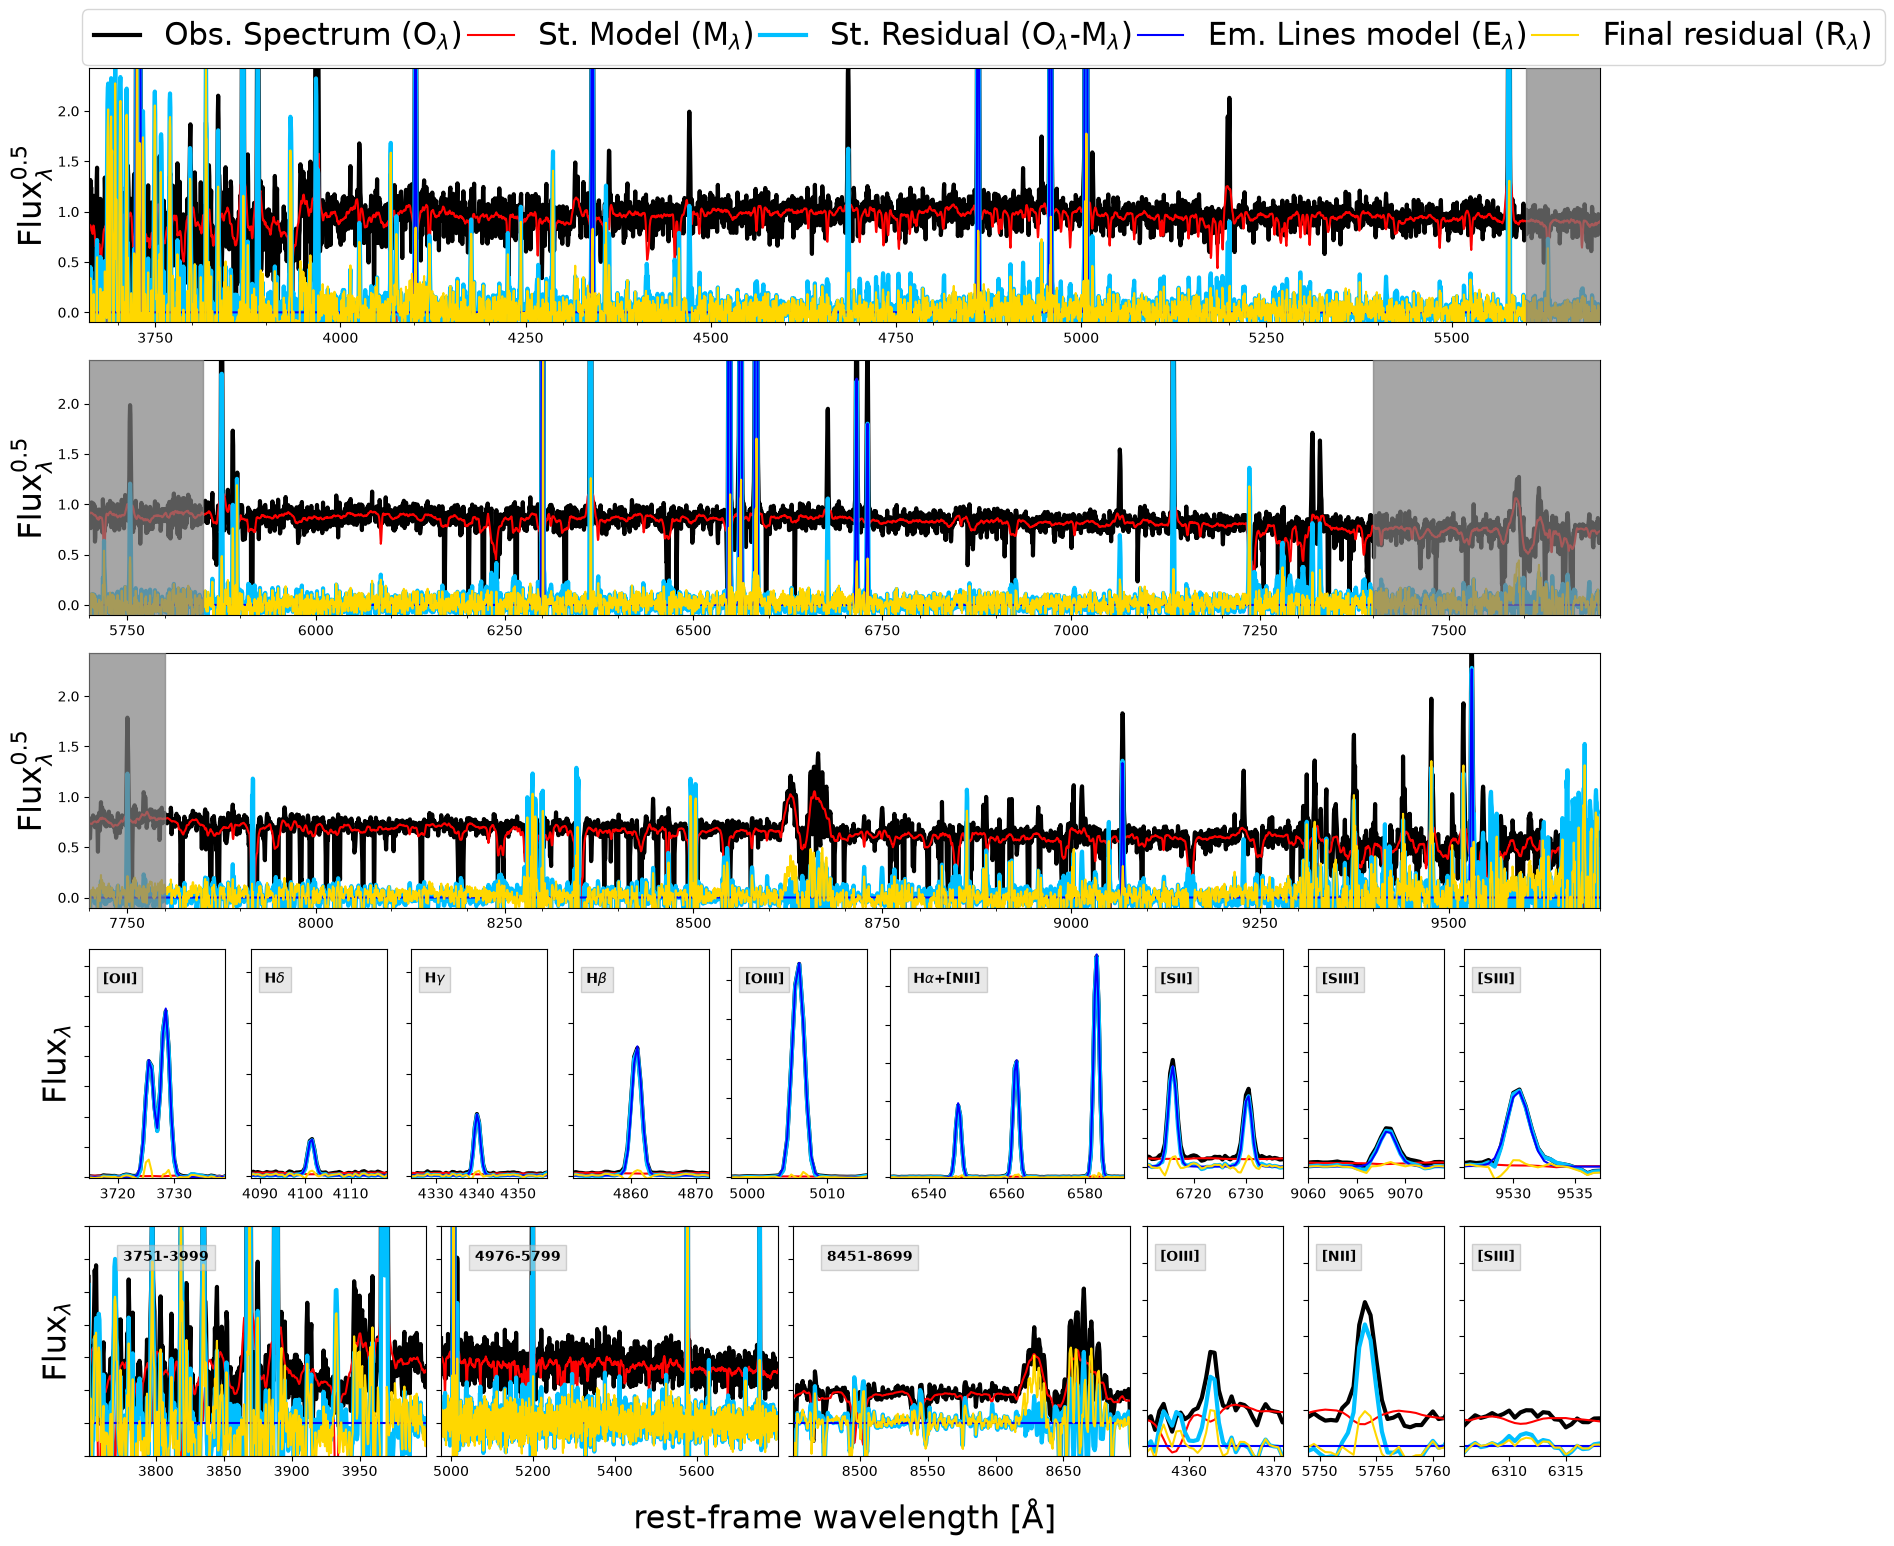

In [15]:
ranges = (3661, 5700, 7700, 9700)       # edges of the three panels

INSET_H = 0.9
row1_y, row2_y = -3.36, -4.45           # inset rows below the first panel (its axes units)
# (x0, width, wl_min, wl_max, f_min, f_max, label)
row1 = [(0.000, 0.090, 3715, 3739, -1.0, 189, '[OII]'),
        (0.107, 0.090, 4088, 4118, -1.0,  89, r'H$\delta$'),
        (0.213, 0.090, 4324, 4357, -1.0,  89, r'H$\gamma$'),
        (0.320, 0.090, 4851, 4872, -1.0,  89, r'H$\beta$'),
        (0.425, 0.090, 4998, 5015, -1.0, 289, '[OIII]'),
        (0.530, 0.155, 6530, 6590, -1.0, 299, r'H$\alpha$+[NII]'),
        (0.700, 0.090, 6711, 6737, -1.0,  19, '[SII]'),
        (0.807, 0.090, 9060, 9074, -1.0,  19, '[SIII]'),
        (0.910, 0.090, 9526, 9537, -1.0,  19, '[SIII]')]
row2 = [(0.000, 0.223, 3751, 3999, -0.5, 3, '3751-3999'),
        (0.233, 0.223, 4976, 5799, -0.5, 3, '4976-5799'),
        (0.466, 0.223, 8451, 8699, -0.5, 3, '8451-8699'),
        (0.700, 0.090, 4363 - 8, 4363 + 8, -0.25, 6, '[OIII]'),
        (0.807, 0.090, 5755 - 6, 5755 + 6, -0.25, 6, '[NII]'),
        (0.910, 0.090, 6312 - 6, 6312 + 6, -0.25, 6, '[SIII]')]
insets = [(x, y, w, INSET_H, *rest)
          for y, row in ((row1_y, row1), (row2_y, row2))
          for x, w, *rest in row]

fig = plot_spec_now_3pg(av_spec, wave, insets=insets,
                        x_min=ranges[:-1], x_max=ranges[1:],
                        y_min=-0.01, y_max=5.9, gamma=0.5, alpha=1.0, plot_res=True)
# fig.savefig('figs/m_Helix_DR20.png', facecolor='white')
plt.show()

### About this notebook

This notebook shows how to read and visualize the reconstructed spectral components in an
LVM DR20 DAP model file.

**Authors**: Sebastian F. Sanchez and the LVM team

**Last Update**: 2026 May 12

If you use `astropy` for published research, please
[cite the authors](https://www.astropy.org/acknowledging.html), and please
[cite SDSS](https://sdss.org/collaboration/citing-sdss/) when you use our data.